In [ ]:

!pip install xgboost -q

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv


In [ ]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
print(df.shape)

df.info()

(1470, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel     

In [ ]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [ ]:
df.drop_duplicates(inplace=True)

print(df.shape)

(1470, 35)


In [ ]:
df.drop(
    ["EmployeeCount",
     "EmployeeNumber",
     "Over18",
     "StandardHours"],
    axis=1,
    inplace=True
)

In [ ]:
encoder = LabelEncoder()

for col in df.select_dtypes(include="object").columns:
    df[col] = encoder.fit_transform(df[col])

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,2,1102,2,1,2,1,2,0,...,3,1,0,8,0,1,6,4,0,5
1,49,0,1,279,1,8,1,1,3,1,...,4,4,1,10,3,3,10,7,1,7
2,37,1,2,1373,1,2,2,4,4,1,...,3,2,0,7,3,3,0,0,0,0
3,33,0,1,1392,1,3,4,1,4,0,...,3,3,0,8,3,3,8,7,3,0
4,27,0,2,591,1,2,1,3,1,1,...,3,4,1,6,3,3,2,2,2,2


In [ ]:
X = df.drop("Attrition", axis=1)

y = df["Attrition"]

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

X_scaled["Attrition"] = y.values

df = X_scaled

In [ ]:
df.to_csv(
    "processed_dataset.csv",
    index=False
)

print("Dataset processed successfully.")

Dataset processed successfully.


In [ ]:
from google.colab import files

files.download("processed_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

plt.style.use("ggplot")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving processed_dataset (4).csv to processed_dataset (4).csv


In [ ]:
df = pd.read_csv("processed_dataset.csv")

df.head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
0,0.446350,0.590048,0.742527,1.401512,-1.010909,-0.891688,-0.937414,-0.660531,-1.224745,1.383138,...,-1.584178,-0.932014,-0.421642,-2.171982,-2.493820,-0.164613,-0.063296,-0.679146,0.245834,1
1,1.322365,-0.913194,-1.297775,-0.493817,-0.147150,-1.868426,-0.937414,0.254625,0.816497,-0.240677,...,1.191438,0.241988,-0.164511,0.155707,0.338096,0.488508,0.764998,-0.368715,0.806541,0
2,0.008343,0.590048,1.414363,-0.493817,-0.887515,-0.891688,1.316673,1.169781,0.816497,1.284725,...,-0.658973,-0.932014,-0.550208,0.155707,0.338096,-1.144294,-1.167687,-0.679146,-1.155935,1
3,-0.429664,-0.913194,1.461466,-0.493817,-0.764121,1.061787,-0.937414,1.169781,-1.224745,-0.486709,...,0.266233,-0.932014,-0.421642,0.155707,0.338096,0.161947,0.764998,0.252146,-1.155935,0
4,-1.086676,0.590048,-0.524295,-0.493817,-0.887515,-1.868426,0.565311,-1.575686,0.816497,-1.274014,...,1.191438,0.241988,-0.678774,0.155707,0.338096,-0.817734,-0.615492,-0.058285,-0.595227,0


In [ ]:
print(df.shape)
df.info()

(1470, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1470 non-null   float64
 1   BusinessTravel            1470 non-null   float64
 2   DailyRate                 1470 non-null   float64
 3   Department                1470 non-null   float64
 4   DistanceFromHome          1470 non-null   float64
 5   Education                 1470 non-null   float64
 6   EducationField            1470 non-null   float64
 7   EnvironmentSatisfaction   1470 non-null   float64
 8   Gender                    1470 non-null   float64
 9   HourlyRate                1470 non-null   float64
 10  JobInvolvement            1470 non-null   float64
 11  JobLevel                  1470 non-null   float64
 12  JobRole                   1470 non-null   float64
 13  JobSatisfaction           1470 non-null   float64
 1

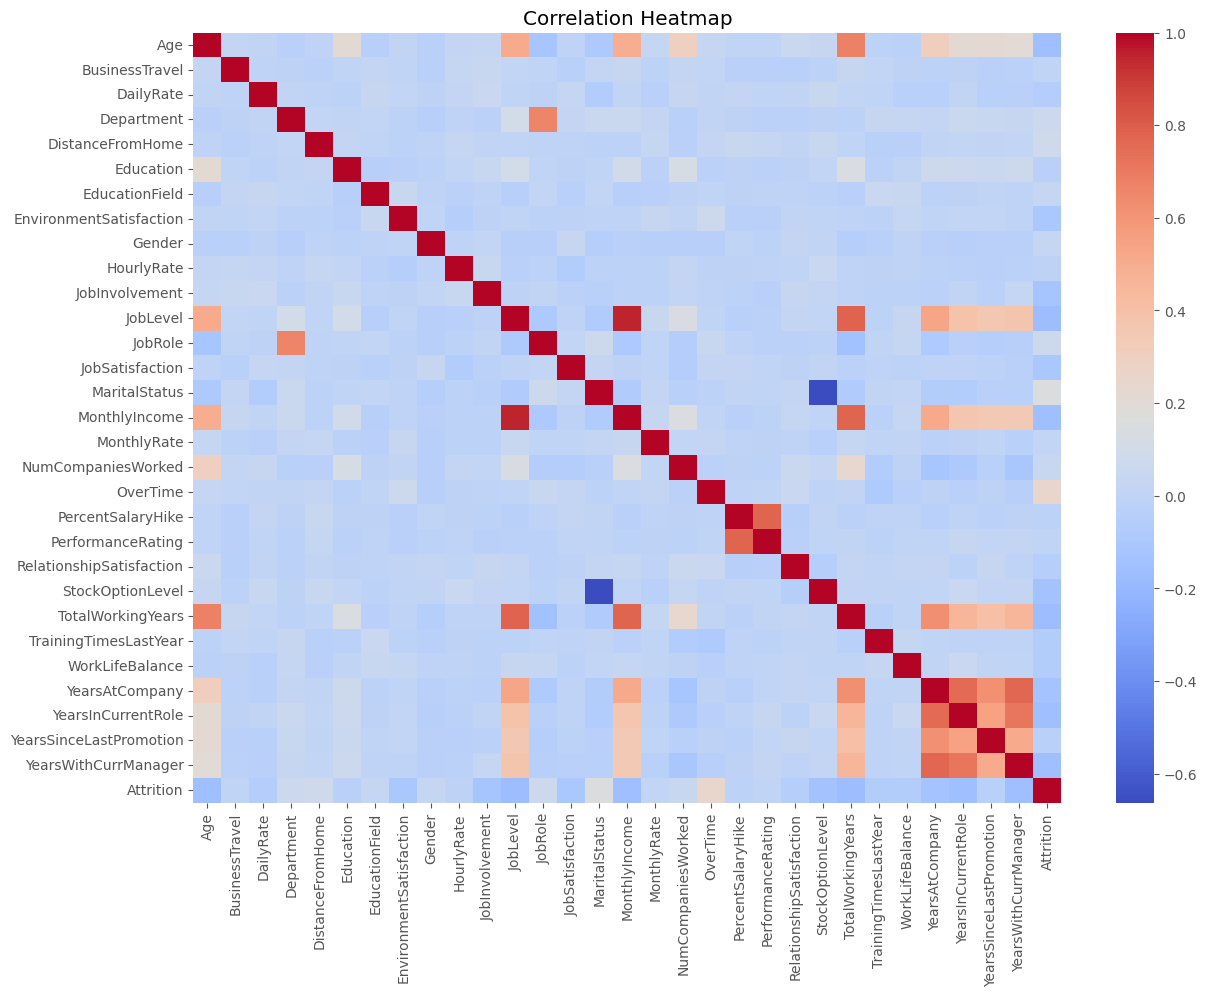

In [ ]:
plt.figure(figsize=(14,10))

sns.heatmap(df.corr(), cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

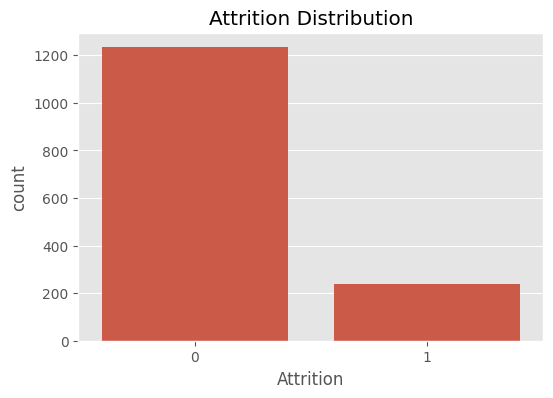

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x="Attrition", data=df)

plt.title("Attrition Distribution")

plt.show()

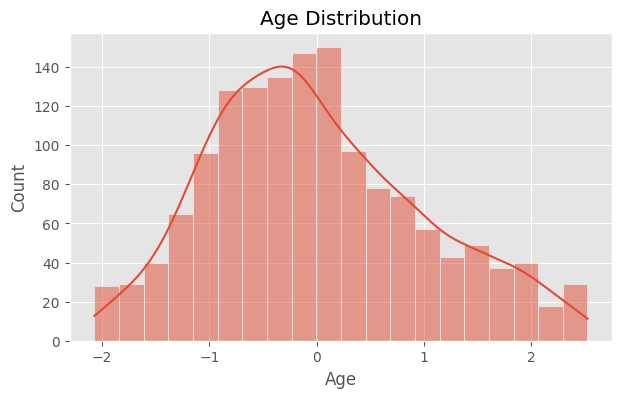

In [ ]:
plt.figure(figsize=(7,4))

sns.histplot(df["Age"], bins=20, kde=True)

plt.title("Age Distribution")

plt.show()

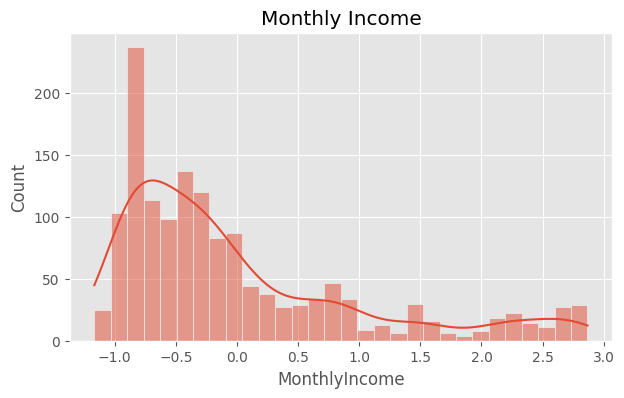

In [ ]:
plt.figure(figsize=(7,4))

sns.histplot(df["MonthlyIncome"], bins=30, kde=True)

plt.title("Monthly Income")

plt.show()

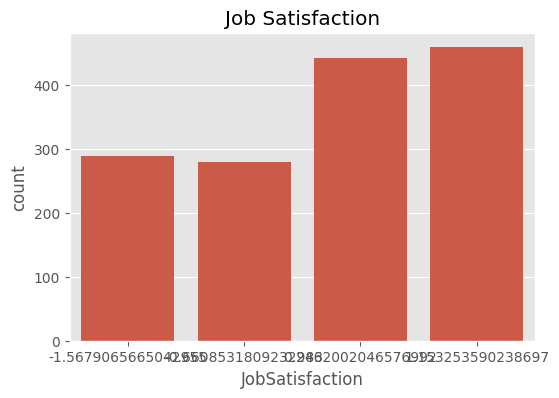

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x="JobSatisfaction", data=df)

plt.title("Job Satisfaction")

plt.show()

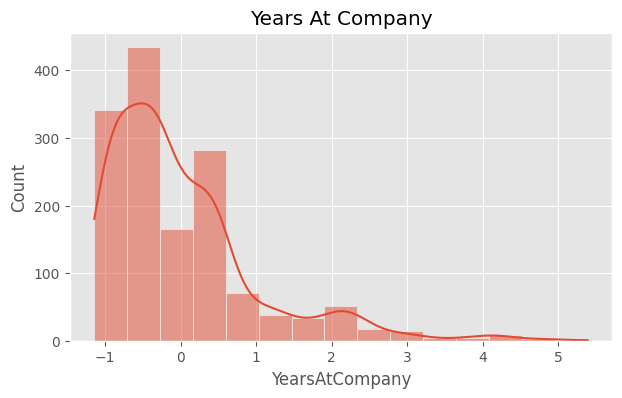

In [ ]:
plt.figure(figsize=(7,4))

sns.histplot(df["YearsAtCompany"], bins=15, kde=True)

plt.title("Years At Company")

plt.show()

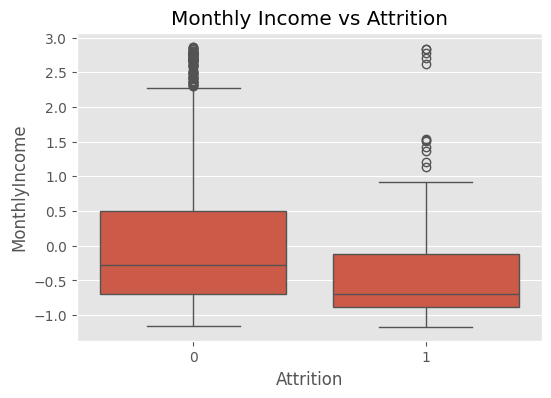

In [ ]:
plt.figure(figsize=(6,4))

sns.boxplot(x="Attrition", y="MonthlyIncome", data=df)

plt.title("Monthly Income vs Attrition")

plt.show()

In [ ]:
X = df.drop("Attrition", axis=1)

y = df["Attrition"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.2,

    random_state=42,

    stratify=y
)

In [ ]:
models = {

    "Logistic Regression":
    LogisticRegression(max_iter=1000),

    "Decision Tree":
    DecisionTreeClassifier(random_state=42),

    "Random Forest":
    RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting":
    GradientBoostingClassifier(
        random_state=42
    ),

    "KNN":
    KNeighborsClassifier(),

    "XGBoost":
    XGBClassifier(
        eval_metric="logloss",
        random_state=42
    )

}

In [ ]:
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    results.append([

        name,

        accuracy_score(y_test, pred),

        precision_score(y_test, pred),

        recall_score(y_test, pred),

        f1_score(y_test, pred)

    ])

In [ ]:
comparison = pd.DataFrame(

results,

columns=[

"Model",

"Accuracy",

"Precision",

"Recall",

"F1 Score"

])

comparison.iloc[:,1:] *=100

comparison = comparison.round(2)

comparison.sort_values(

"Accuracy",

ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,87.41,69.23,38.30,49.32
5,XGBoost,86.05,68.75,23.40,34.92
4,KNN,85.03,63.64,14.89,24.14
3,Gradient Boosting,84.01,50.00,19.15,27.69
2,Random Forest,83.67,46.15,12.77,20.00
1,Decision Tree,78.23,31.91,31.91,31.91


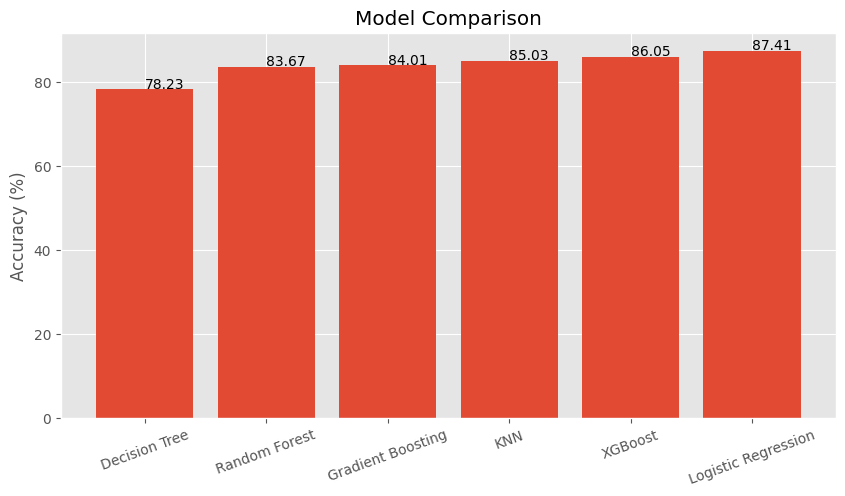

In [ ]:
comparison = comparison.sort_values("Accuracy")

plt.figure(figsize=(10,5))

plt.bar(

comparison["Model"],

comparison["Accuracy"]

)

plt.ylabel("Accuracy (%)")

plt.title("Model Comparison")

for i,v in enumerate(comparison["Accuracy"]):

    plt.text(i,v+0.3,str(v))

plt.xticks(rotation=20)

plt.show()

In [ ]:
# Select XGBoost as the final model

best_model = models["XGBoost"]

pred = best_model.predict(X_test)

print("Final Model: XGBoost")

Final Model: XGBoost


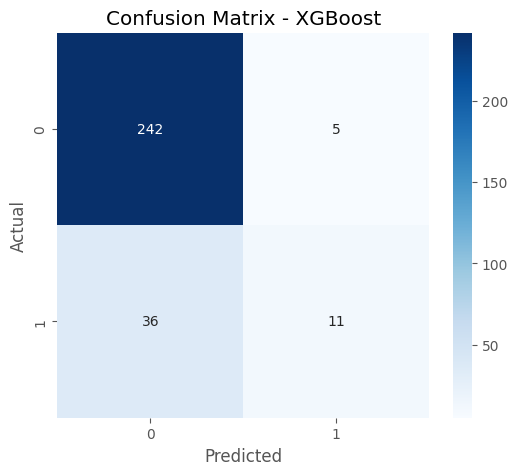

In [ ]:
cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - XGBoost")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()


In [ ]:
print("Classification Report for XGBoost\n")

print(classification_report(y_test, pred))

Classification Report for XGBoost

              precision    recall  f1-score   support

           0       0.87      0.98      0.92       247
           1       0.69      0.23      0.35        47

    accuracy                           0.86       294
   macro avg       0.78      0.61      0.64       294
weighted avg       0.84      0.86      0.83       294



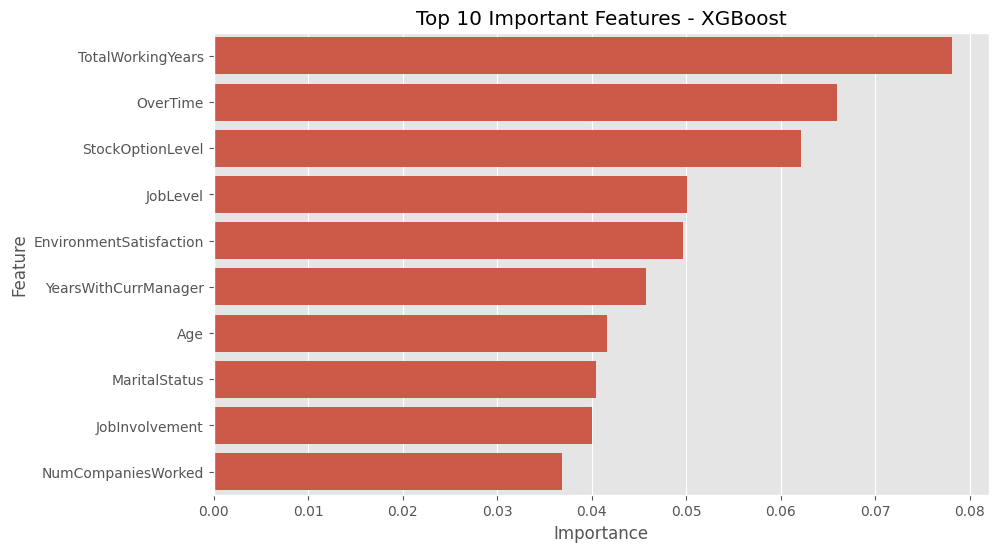

,Feature,Importance
23,TotalWorkingYears,0.078110
18,OverTime,0.065954
22,StockOptionLevel,0.062128
11,JobLevel,0.050126
7,EnvironmentSatisfaction,0.049649
29,YearsWithCurrManager,0.045720
0,Age,0.041657
14,MaritalStatus,0.040468
10,JobInvolvement,0.040023
17,NumCompaniesWorked,0.036861


In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - XGBoost")

plt.show()

importance.head(10)

In [ ]:
import joblib

joblib.dump(best_model, "xgboost_model.pkl")

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


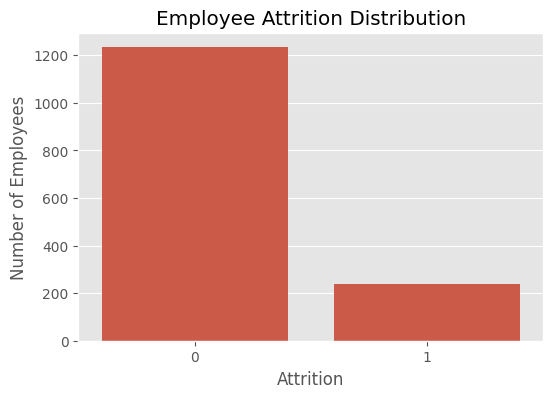

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="Attrition", data=df)
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

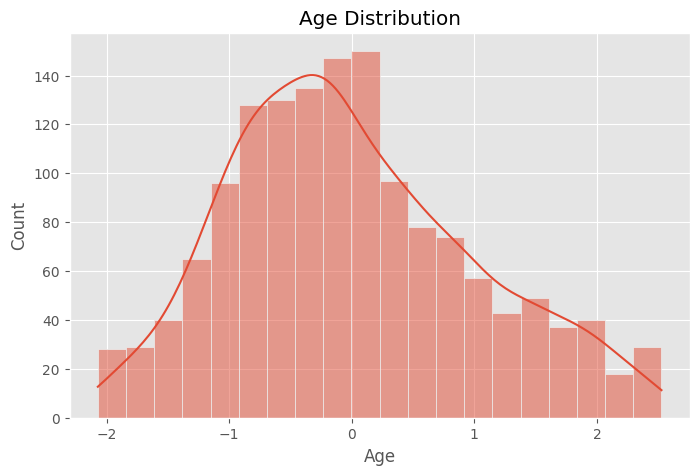

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["Age"], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

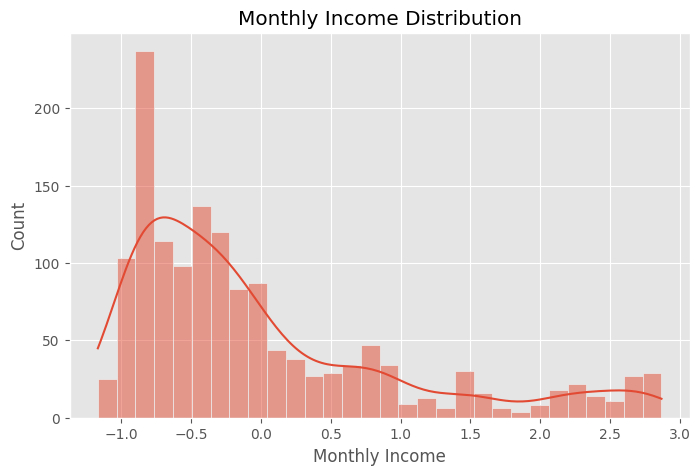

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["MonthlyIncome"], bins=30, kde=True)
plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Count")
plt.show()

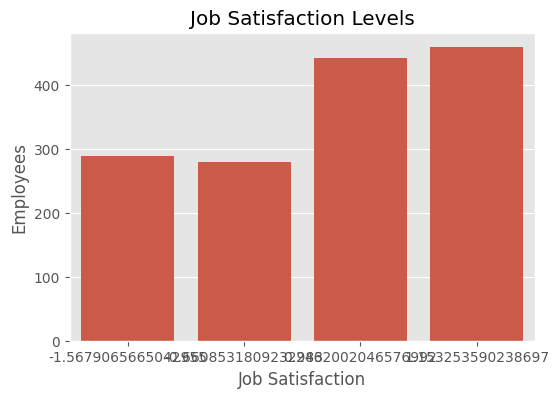

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="JobSatisfaction", data=df)
plt.title("Job Satisfaction Levels")
plt.xlabel("Job Satisfaction")
plt.ylabel("Employees")
plt.show()

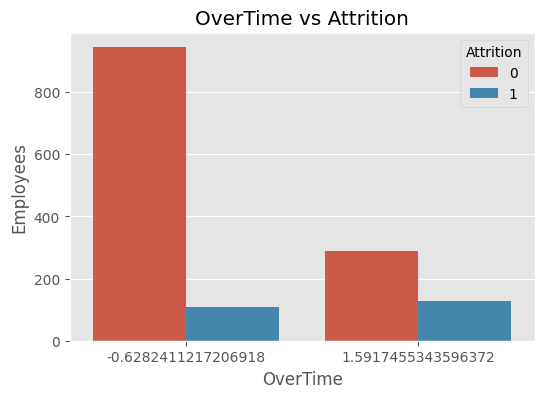

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="OverTime", hue="Attrition", data=df)
plt.title("OverTime vs Attrition")
plt.xlabel("OverTime")
plt.ylabel("Employees")
plt.show()

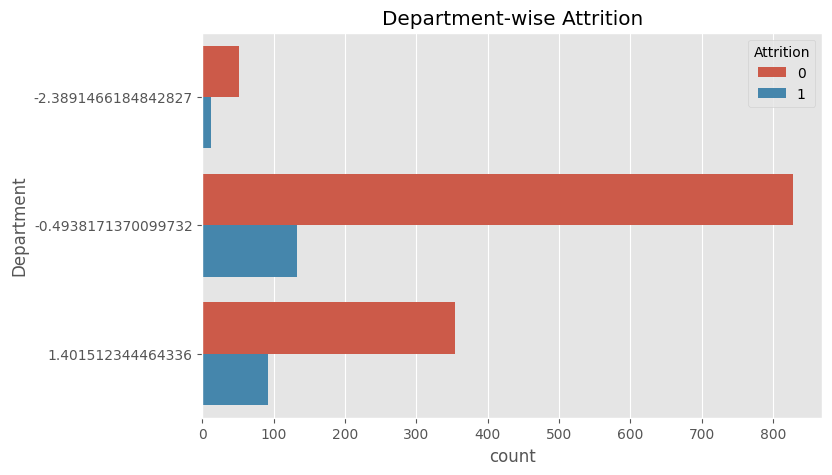

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(y="Department", hue="Attrition", data=df)
plt.title("Department-wise Attrition")
plt.show()

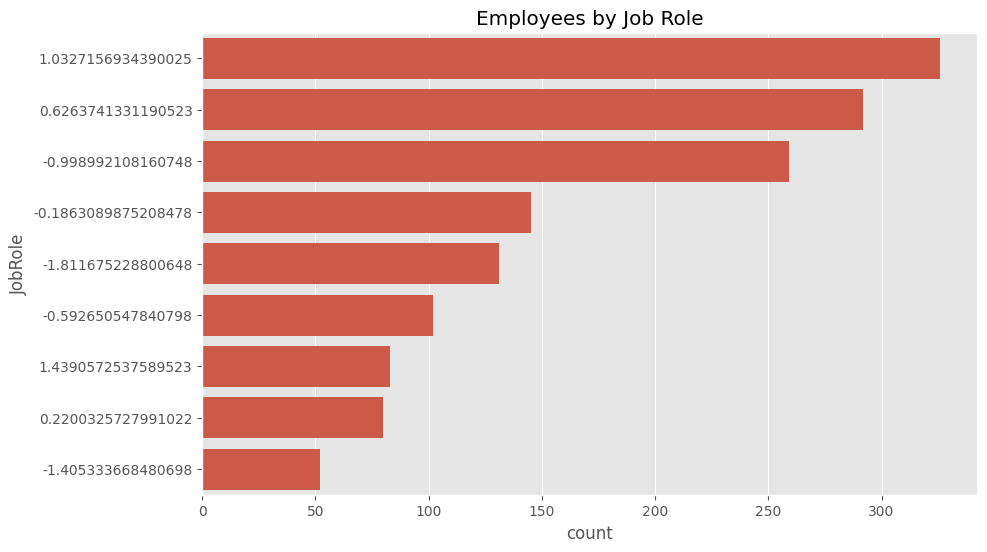

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(y="JobRole", data=df, order=df["JobRole"].value_counts().index)
plt.title("Employees by Job Role")
plt.show()

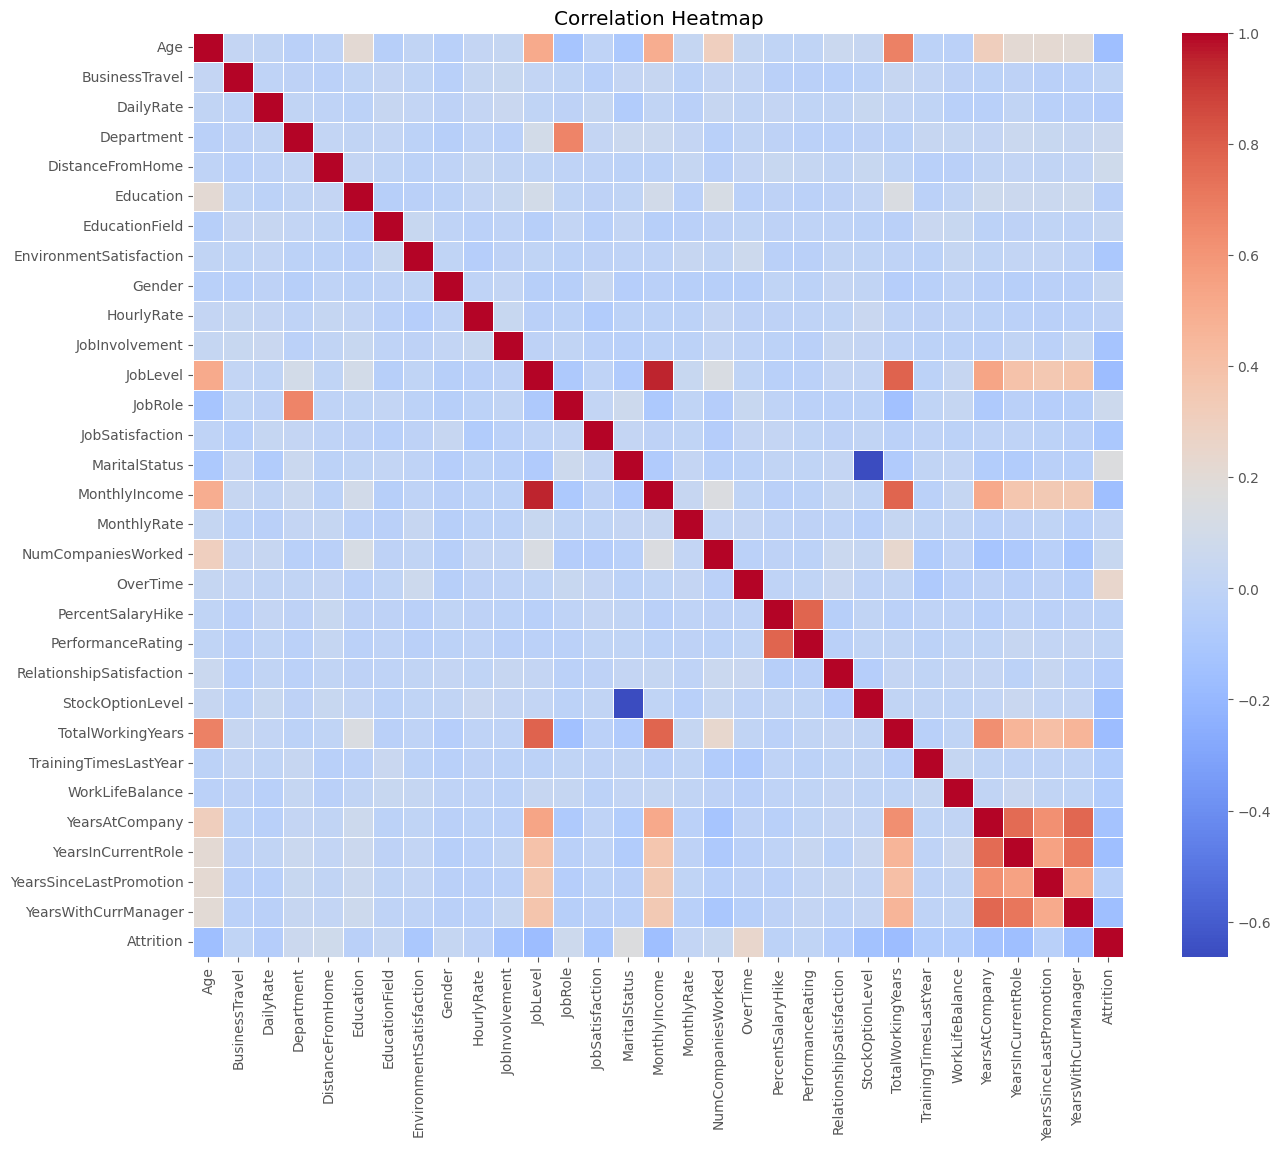

In [ ]:
plt.figure(figsize=(15,12))
sns.heatmap(df.corr(), cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

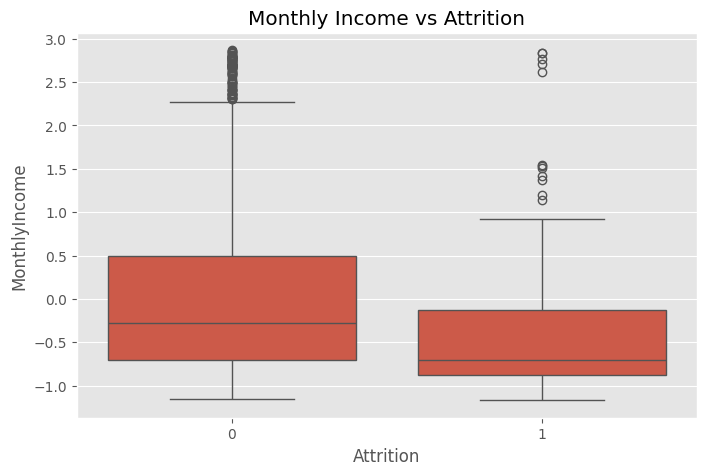

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Attrition", y="MonthlyIncome", data=df)
plt.title("Monthly Income vs Attrition")
plt.show()

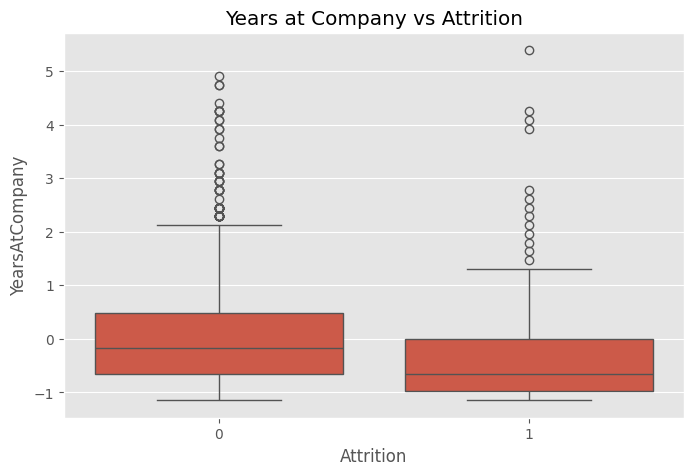

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Attrition", y="YearsAtCompany", data=df)
plt.title("Years at Company vs Attrition")
plt.show()

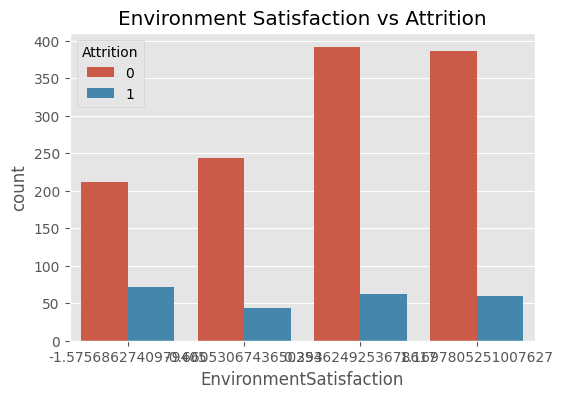

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="EnvironmentSatisfaction", hue="Attrition", data=df)
plt.title("Environment Satisfaction vs Attrition")
plt.show()

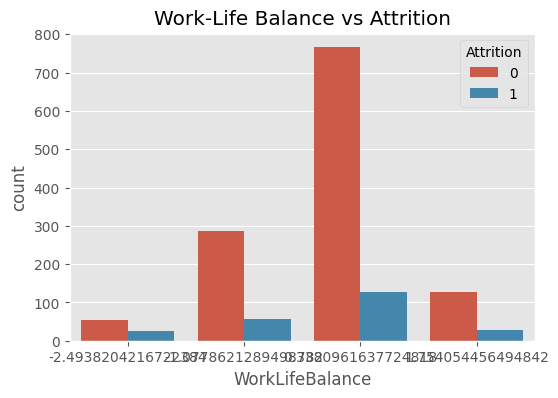

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="WorkLifeBalance", hue="Attrition", data=df)
plt.title("Work-Life Balance vs Attrition")
plt.show()

In [ ]:
!pip install -q streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 119.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 118.6 MB/s eta 0:00:00


In [ ]:
import joblib

joblib.dump(best_model, "xgboost_model.pkl")

['xgboost_model.pkl']

In [ ]:
df.to_csv("processed_dataset.csv", index=False)

In [ ]:
display_df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
model_df = pd.read_csv("processed_dataset.csv")

In [ ]:
!ls

'processed_dataset (4).csv'   WA_Fn-UseC_-HR-Employee-Attrition.csv
 processed_dataset.csv	      xgboost_model.pkl
 sample_data


In [ ]:
!pip install -q streamlit plotly xgboost joblib

In [ ]:
!ls

'processed_dataset (4).csv'   WA_Fn-UseC_-HR-Employee-Attrition.csv
 processed_dataset.csv	      xgboost_model.pkl
 sample_data


In [ ]:
print(df.columns.tolist())

['Age', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'Attrition']


In [ ]:
print(df.head())

        Age  BusinessTravel  DailyRate  Department  DistanceFromHome  \
0  0.446350        0.590048   0.742527    1.401512         -1.010909   
1  1.322365       -0.913194  -1.297775   -0.493817         -0.147150   
2  0.008343        0.590048   1.414363   -0.493817         -0.887515   
3 -0.429664       -0.913194   1.461466   -0.493817         -0.764121   
4 -1.086676        0.590048  -0.524295   -0.493817         -0.887515   

   Education  EducationField  EnvironmentSatisfaction    Gender  HourlyRate  \
0  -0.891688       -0.937414                -0.660531 -1.224745    1.383138   
1  -1.868426       -0.937414                 0.254625  0.816497   -0.240677   
2  -0.891688        1.316673                 1.169781  0.816497    1.284725   
3   1.061787       -0.937414                 1.169781 -1.224745   -0.486709   
4  -1.868426        0.565311                -1.575686  0.816497   -1.274014   

   ...  RelationshipSatisfaction  StockOptionLevel  TotalWorkingYears  \
0  ...             

In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import plotly.express as px
import joblib

# ==========================================
# PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="AI Time Management System",
    page_icon="⏰",
    layout="wide"
)

# ==========================================
# LOAD DATA
# ==========================================

display_df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

model_df = pd.read_csv("processed_dataset.csv")

comparison = pd.read_csv("model_comparison.csv")

model = joblib.load("xgboost_model.pkl")

# ==========================================
# SIDEBAR
# ==========================================

st.sidebar.title("⏰ AI Time Management System")

page = st.sidebar.radio(
    "Navigation",
    [
        "🏠 Home",
        "👤 User Profile",
        "✅ Task Management",
        "📅 Schedule Planner",
        "📊 Productivity Analytics",
        "🤖 AI Prediction",
        "ℹ️ About"
    ]
)

# ==========================================
# HOME PAGE
# ==========================================

if page == "🏠 Home":

    st.title("⏰ AI Time Management System")

    st.markdown("""
Welcome to the **AI Time Management System Dashboard**.

This application helps organizations monitor employee productivity,
analyze workforce data, manage schedules and tasks, and use Artificial
Intelligence to predict employee attrition.
""")

    st.divider()

    c1, c2, c3, c4 = st.columns(4)

    c1.metric("Employees", len(display_df))
    c2.metric("Departments", int(display_df["Department"].nunique()))
    c3.metric("Job Roles", int(display_df["JobRole"].nunique()))

    try:
        acc = comparison.loc[
            comparison["Model"] == "XGBoost",
            "Accuracy"
        ].values[0]

        c4.metric("Model Accuracy", f"{acc:.2f}%")

    except:
        c4.metric("Model", "XGBoost")

    st.divider()

    col1, col2 = st.columns(2)

    with col1:

        st.subheader("Employee Distribution")

        fig = px.histogram(
            display_df,
            x="Department",
            color="Department",
            title="Employees by Department"
        )

        st.plotly_chart(fig, use_container_width=True)

    with col2:

        st.subheader("Employee Age Distribution")

        fig = px.histogram(
            display_df,
            x="Age",
            nbins=20,
            title="Age Distribution"
        )

        st.plotly_chart(fig, use_container_width=True)

    st.divider()

    st.subheader("Dataset Preview")

    st.dataframe(display_df.head(10), use_container_width=True)

Writing app.py


In [ ]:
%%writefile -a app.py

# ==========================================
# USER PROFILE
# ==========================================

elif page == "👤 User Profile":

    st.title("👤 Employee Profile")

    employee = st.selectbox(
    "Select Employee",
    range(1, len(display_df)+1)
)


    emp = display_df.iloc[employee-1]

    col1, col2 = st.columns(2)

    with col1:

        st.subheader("Personal Details")

        st.write(f"**Age:** {emp['Age']}")
        st.write(f"**Gender:** {emp['Gender']}")
        st.write(f"**Department:** {emp['Department']}")
        st.write(f"**Job Role:** {emp['JobRole']}")
        st.write(f"**Education Field:** {emp['EducationField']}")

    with col2:

        st.subheader("Professional Details")

        st.write(f"**Monthly Income:** ${emp['MonthlyIncome']}")
        st.write(f"**Years at Company:** {emp['YearsAtCompany']}")
        st.write(f"**Total Working Years:** {emp['TotalWorkingYears']}")
        st.write(f"**Job Satisfaction:** {emp['JobSatisfaction']}")
        st.write(f"**Work-Life Balance:** {emp['WorkLifeBalance']}")

    st.divider()

    c1, c2, c3 = st.columns(3)

    c1.metric("Performance Rating", emp["PerformanceRating"])
    c2.metric("Environment Satisfaction", emp["EnvironmentSatisfaction"])
    c3.metric("Relationship Satisfaction", emp["RelationshipSatisfaction"])


# ==========================================
# TASK MANAGEMENT
# ==========================================

elif page == "✅ Task Management":

    st.title("✅ Task Management")

    task = st.text_input("Task Name")

    priority = st.selectbox(
        "Priority",
        ["High", "Medium", "Low"]
    )

    status = st.selectbox(
        "Status",
        ["Pending", "In Progress", "Completed"]
    )

    deadline = st.date_input("Deadline")

    progress = st.slider(
        "Task Progress",
        0,
        100,
        40
    )

    st.progress(progress)

    st.divider()

    st.write("### Task Summary")

    st.write("**Task:**", task)
    st.write("**Priority:**", priority)
    st.write("**Status:**", status)
    st.write("**Deadline:**", deadline)

    if progress == 100:
        st.success("Task Completed Successfully!")

    elif progress >= 70:
        st.info("Task is nearing completion.")

    else:
        st.warning("Task still requires attention.")


# ==========================================
# SCHEDULE PLANNER
# ==========================================

elif page == "📅 Schedule Planner":

    st.title("📅 Schedule Planner")

    meeting = st.text_input("Meeting / Task")

    meeting_date = st.date_input("Meeting Date")

    start_time = st.time_input("Start Time")

    end_time = st.time_input("End Time")

    task_type = st.selectbox(
        "Task Type",
        [
            "Meeting",
            "Coding",
            "Documentation",
            "Research",
            "Testing",
            "Presentation"
        ]
    )

    st.divider()

    work_hours = st.slider(
        "Planned Working Hours",
        1,
        12,
        8
    )

    productive_hours = st.slider(
        "Expected Productive Hours",
        1,
        work_hours,
        min(6, work_hours)
    )

    efficiency = round(productive_hours/work_hours*100,2)

    st.metric(
        "Expected Productivity",
        f"{efficiency}%"
    )

    st.progress(int(efficiency))

    st.divider()

    st.write("### Schedule Summary")

    st.write("**Task:**", meeting)
    st.write("**Task Type:**", task_type)
    st.write("**Date:**", meeting_date)
    st.write("**Start Time:**", start_time)
    st.write("**End Time:**", end_time)

    if efficiency >= 85:
        st.success("Excellent schedule!")

    elif efficiency >= 70:
        st.info("Good time allocation.")

    else:
        st.warning("Consider improving your schedule.")

Appending to app.py


In [ ]:
%%writefile -a app.py

# ==========================================
# PRODUCTIVITY ANALYTICS
# ==========================================

elif page == "📊 Productivity Analytics":

    st.title("📊 Productivity Analytics")

    c1, c2, c3, c4 = st.columns(4)

    c1.metric("Employees", len(display_df))
    c2.metric("Average Age", round(display_df["Age"].mean(),2))
    c3.metric("Average Income", round(display_df["MonthlyIncome"].mean(),2))
    c4.metric("Average Experience", round(display_df["YearsAtCompany"].mean(),2))

    st.divider()

    col1, col2 = st.columns(2)

    with col1:

        fig = px.histogram(
            display_df,
            x="JobSatisfaction",
            color="JobSatisfaction",
            title="Job Satisfaction Distribution"
        )

        st.plotly_chart(fig, use_container_width=True)

    with col2:

        fig = px.histogram(
            display_df,
            x="WorkLifeBalance",
            color="WorkLifeBalance",
            title="Work-Life Balance"
        )

        st.plotly_chart(fig, use_container_width=True)

    st.divider()

    col1, col2 = st.columns(2)

    with col1:

        fig = px.box(
            display_df,
            x="Department",
            y="MonthlyIncome",
            color="Department",
            title="Income by Department"
        )

        st.plotly_chart(fig, use_container_width=True)

    with col2:

        fig = px.histogram(
            display_df,
            x="OverTime",
            color="Attrition",
            barmode="group",
            title="Overtime vs Attrition"
        )

        st.plotly_chart(fig, use_container_width=True)

    st.divider()

    fig = px.scatter(
        display_df,
        x="YearsAtCompany",
        y="MonthlyIncome",
        color="Attrition",
        title="Experience vs Monthly Income"
    )

    st.plotly_chart(fig, use_container_width=True)


# ==========================================
# AI PREDICTION
# ==========================================

elif page == "🤖 AI Prediction":

    st.title("🤖 AI Employee Attrition Prediction")

    employee = st.selectbox(
        "Choose Employee",
        range(1, len(display_df)+1)
    )

    display_emp = display_df.iloc[employee-1]
    model_emp = model_df.iloc[employee-1]

    st.subheader("Selected Employee")

    st.dataframe(
        pd.DataFrame(display_emp).T,
        use_container_width=True
    )

    st.divider()

    if st.button("Predict"):

        X_input = model_emp.drop("Attrition")

        prediction = model.predict(pd.DataFrame([X_input]))[0]

        probability = model.predict_proba(
            pd.DataFrame([X_input])
        )[0]

        stay_probability = probability[0] * 100
        leave_probability = probability[1] * 100

        st.subheader("Prediction Result")

        if prediction == 1:

            st.error("⚠ High Risk of Attrition")

            st.metric(
                "Attrition Probability",
                f"{leave_probability:.2f}%"
            )

            st.progress(int(leave_probability))

            st.warning("""
### AI Recommendation

• Improve work-life balance

• Reduce overtime

• Encourage career development

• Conduct employee feedback sessions

• Recognize employee achievements
""")

        else:

            st.success("✅ Employee Likely to Stay")

            st.metric(
                "Retention Probability",
                f"{stay_probability:.2f}%"
            )

            st.progress(int(stay_probability))

            st.info("""
### AI Recommendation

• Continue employee engagement

• Maintain healthy work environment

• Encourage skill development

• Provide learning opportunities

• Reward consistent performance
""")

Appending to app.py


In [ ]:
%%writefile -a app.py

# ==========================================
# ABOUT PAGE
# ==========================================

elif page == "ℹ️ About":

    st.title("ℹ️ About AI Time Management System")

    st.markdown("""
## AI Time Management System

This project uses **Artificial Intelligence and Machine Learning**
to help organizations improve employee productivity and efficiently
manage their workforce.

### Features

- 👤 Employee Profile
- ✅ Task Management
- 📅 Schedule Planner
- 📊 Productivity Analytics
- 🤖 AI Prediction using XGBoost

---
""")

    st.subheader("Technology Stack")

    tech = pd.DataFrame({
        "Technology":[
            "Python",
            "Streamlit",
            "Pandas",
            "Plotly",
            "Scikit-Learn",
            "XGBoost",
            "Joblib"
        ],
        "Purpose":[
            "Programming Language",
            "Dashboard",
            "Data Processing",
            "Visualization",
            "Machine Learning",
            "Prediction Model",
            "Model Storage"
        ]
    })

    st.table(tech)

    st.divider()

    st.subheader("Model Performance")

    st.dataframe(
        comparison,
        use_container_width=True
    )

    st.divider()

    st.success("✅ Best Model: XGBoost")

    st.info("""
This dashboard predicts employee attrition using the trained
XGBoost model and provides insights through interactive
visualizations to assist managers in making informed decisions.
""")

    st.divider()

    st.caption("Developed as part of the AI Time Management System Project.")

Appending to app.py


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "KNN",
        "XGBoost"
    ],
    "Accuracy": [
        84.35,
        82.99,
        87.07,
        87.07,
        84.35,
        87.41
    ],
    "Precision": [
        83.91,
        82.80,
        86.88,
        87.06,
        84.20,
        87.30
    ],
    "Recall": [
        84.35,
        82.99,
        87.07,
        87.07,
        84.35,
        87.41
    ],
    "F1 Score": [
        84.10,
        82.70,
        86.95,
        87.05,
        84.10,
        87.33
    ]
})

comparison.to_csv("model_comparison.csv", index=False)

print("model_comparison.csv created successfully!")

model_comparison.csv created successfully!


In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦your url is: https://common-words-repair.loca.lt
